<a href="https://colab.research.google.com/github/gunaseelank2801-arch/Student-Performance-Prediction/blob/main/Guna_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
print("Welcome to Student Performance Prediction!")
print("Machine Learning Project Started Successfully!")

Welcome to Student Performance Prediction!
Machine Learning Project Started Successfully!


In [ ]:
from google.colab import files
import pandas as pd

uploaded = files.upload()

file_name = next(iter(uploaded))

df = pd.read_csv(file_name)

print("Dataset uploaded successfully!")
print("Total records:", len(df))

display(df.head())

Saving student_performance_prediction.csv to student_performance_prediction (3).csv
Dataset uploaded successfully!
Total records: 40000


,Student ID,Study Hours per Week,Attendance Rate,Previous Grades,Participation in Extracurricular Activities,Parent Education Level,Passed
0,S00001,12.5,NaN,75.0,Yes,Master,Yes
1,S00002,9.3,95.3,60.6,No,High School,No
2,S00003,13.2,NaN,64.0,No,Associate,No
3,S00004,17.6,76.8,62.4,Yes,Bachelor,No
4,S00005,8.8,89.3,72.7,No,Master,No


In [ ]:
# Data handling
import pandas as pd
import numpy as np

# Data visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# ML algorithms
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

# Interactive dashboard
import ipywidgets as widgets
from IPython.display import display, clear_output

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
print("DATASET INFORMATION")

print("\nNumber of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nPass/Fail Distribution:")
print(df["Passed"].value_counts(dropna=False))

DATASET INFORMATION

Number of Rows: 40000
Number of Columns: 7

Column Names:
['Student ID', 'Study Hours per Week', 'Attendance Rate', 'Previous Grades', 'Participation in Extracurricular Activities', 'Parent Education Level', 'Passed']

Data Types:
Student ID                                      object
Study Hours per Week                           float64
Attendance Rate                                float64
Previous Grades                                float64
Participation in Extracurricular Activities     object
Parent Education Level                          object
Passed                                          object
dtype: object

Statistical Summary:


,Study Hours per Week,Attendance Rate,Previous Grades
count,38005.000000,38008.000000,38006.000000
mean,9.962744,75.276323,65.440107
std,5.031154,20.393418,16.503119
min,-12.300000,-14.300000,8.300000
25%,6.600000,61.600000,55.100000
50%,10.000000,75.300000,65.200000
75%,13.400000,88.800000,75.200000
max,32.400000,150.200000,200.000000



Missing Values:
Student ID                                        0
Study Hours per Week                           1995
Attendance Rate                                1992
Previous Grades                                1994
Participation in Extracurricular Activities    2000
Parent Education Level                         2000
Passed                                         2000
dtype: int64

Pass/Fail Distribution:
Passed
Yes    19011
No     18989
NaN     2000
Name: count, dtype: int64


In [ ]:
# Create a working copy
data = df.copy()

# Remove unnecessary Student ID
data.drop(columns=["Student ID"], inplace=True)

# Convert numerical columns
numeric_columns = [
    "Study Hours per Week",
    "Attendance Rate",
    "Previous Grades"
]

for col in numeric_columns:
    data[col] = pd.to_numeric(data[col], errors="coerce")

# Correct invalid numerical values
data.loc[
    (data["Study Hours per Week"] < 0) |
    (data["Study Hours per Week"] > 168),
    "Study Hours per Week"
] = np.nan

data.loc[
    (data["Attendance Rate"] < 0) |
    (data["Attendance Rate"] > 100),
    "Attendance Rate"
] = np.nan

data.loc[
    (data["Previous Grades"] < 0) |
    (data["Previous Grades"] > 100),
    "Previous Grades"
] = np.nan

# Remove records without a known target
data = data.dropna(subset=["Passed"]).copy()

# Clean target labels
data["Passed"] = data["Passed"].astype(str).str.strip()

data = data[data["Passed"].isin(["Yes", "No"])]

print("Data cleaning completed!")

print("\nCleaned Dataset Shape:", data.shape)

print("\nRemaining Missing Values:")
print(data.isnull().sum())

Data cleaning completed!

Cleaned Dataset Shape: (38000, 6)

Remaining Missing Values:
Study Hours per Week                           2803
Attendance Rate                                5831
Previous Grades                                2340
Participation in Extracurricular Activities    1902
Parent Education Level                         1898
Passed                                            0
dtype: int64


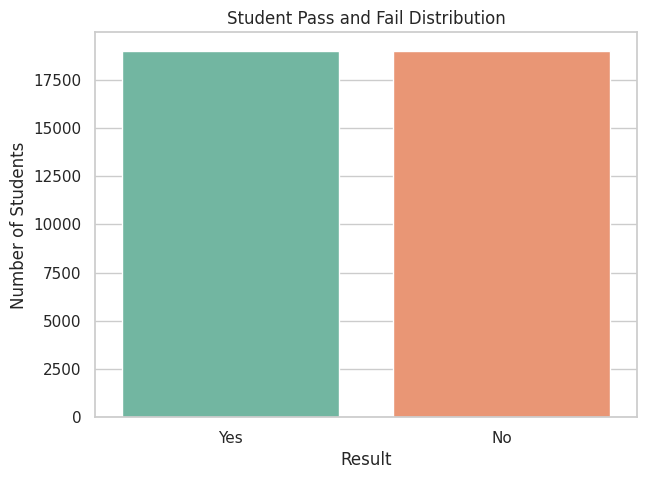

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=data,
    x="Passed",
    hue="Passed",
    palette="Set2",
    legend=False
)

plt.title("Student Pass and Fail Distribution")
plt.xlabel("Result")
plt.ylabel("Number of Students")

plt.show()

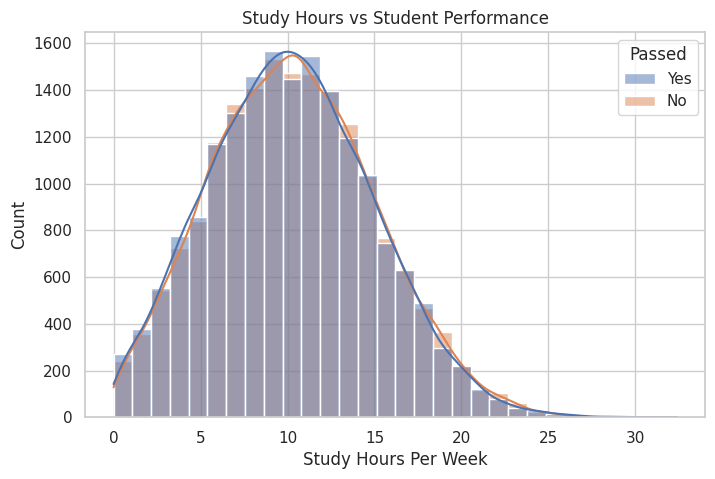

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=data,
    x="Study Hours per Week",
    hue="Passed",
    kde=True,
    bins=30
)

plt.title("Study Hours vs Student Performance")
plt.xlabel("Study Hours Per Week")

plt.show()

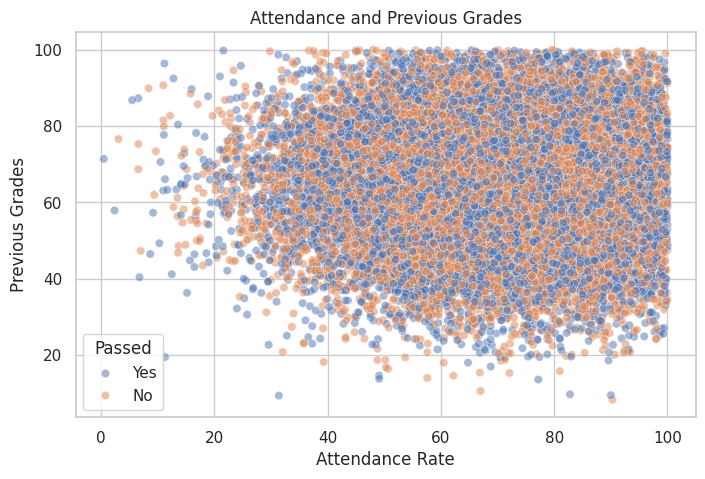

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=data,
    x="Attendance Rate",
    y="Previous Grades",
    hue="Passed",
    alpha=0.5
)

plt.title("Attendance and Previous Grades")
plt.show()

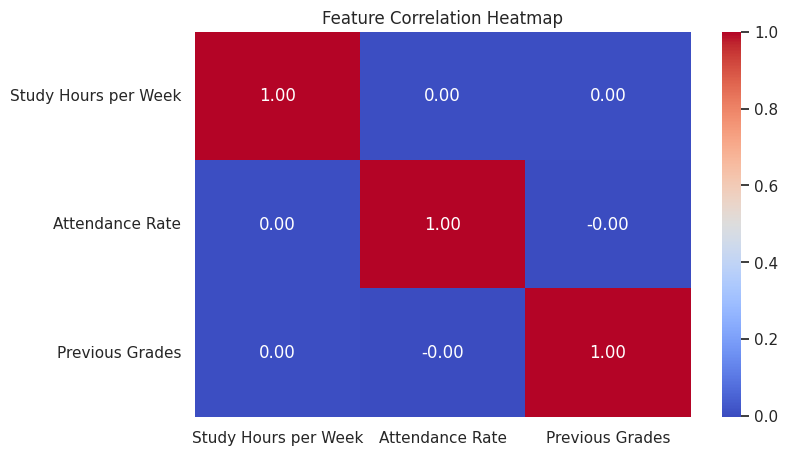

In [ ]:
plt.figure(figsize=(8, 5))

correlation = data[numeric_columns].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Heatmap")
plt.show()

In [ ]:
X = data.drop(columns=["Passed"])

y = data["Passed"].map({
    "No": 0,
    "Yes": 1
})

numeric_features = [
    "Study Hours per Week",
    "Attendance Rate",
    "Previous Grades"
]

categorical_features = [
    "Participation in Extracurricular Activities",
    "Parent Education Level"
]

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Features and target separated successfully!")

print("Input Features:", X.shape)
print("Output Labels:", y.shape)

Features and target separated successfully!
Input Features: (38000, 5)
Output Labels: (38000,)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nData splitting completed!")

Training Data: (30400, 5)
Testing Data: (7600, 5)

Data splitting completed!


In [ ]:
models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=150,
        max_depth=15,
        random_state=42,
        n_jobs=-1
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=10,
        random_state=42
    ),

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    )
}

print("Three ML algorithms created successfully!")

Three ML algorithms created successfully!


In [ ]:
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    print(name, "training completed!")

print("\nAll models trained successfully!")

Random Forest training completed!
Decision Tree training completed!
Logistic Regression training completed!

All models trained successfully!


In [ ]:
results = []

for name, model in trained_models.items():

    predictions = model.predict(X_test)

    probabilities = model.predict_proba(X_test)[:, 1]

    results.append({
        "Algorithm": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

results_df = pd.DataFrame(results)

print("MODEL PERFORMANCE COMPARISON")

display(
    results_df.style.format({
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1 Score": "{:.2%}",
        "ROC-AUC": "{:.2%}"
    }).highlight_max(
        subset=["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"],
        color="lightgreen"
    )
)

MODEL PERFORMANCE COMPARISON


,Algorithm,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest,50.37%,50.39%,51.58%,50.97%,50.21%
1,Decision Tree,50.51%,50.50%,54.73%,52.53%,50.35%
2,Logistic Regression,50.09%,50.12%,50.66%,50.39%,50.53%


<Figure size 1100x600 with 0 Axes>

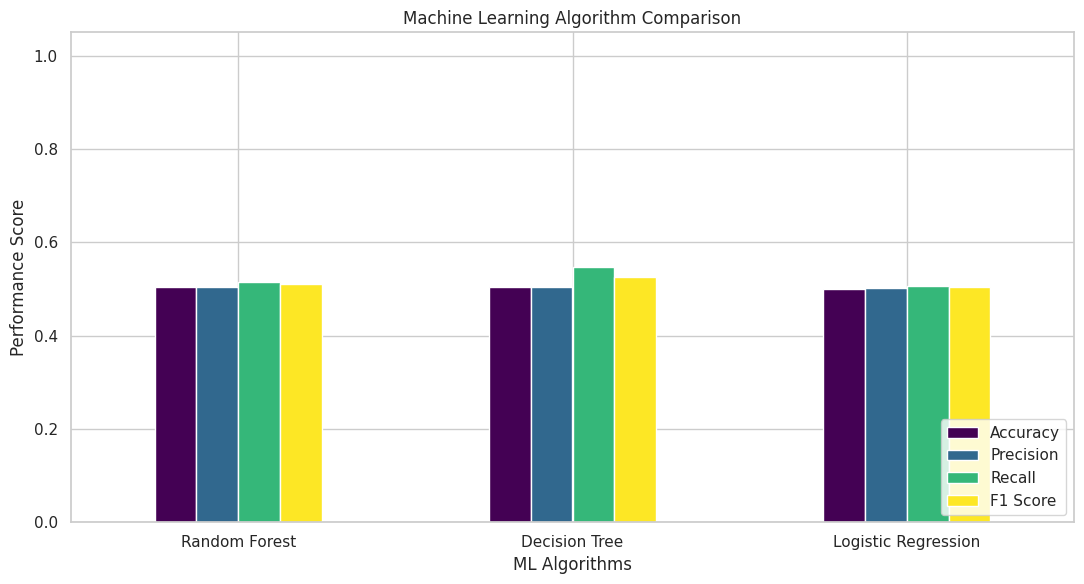

In [ ]:
plt.figure(figsize=(11, 6))

comparison = results_df.set_index("Algorithm")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
]

comparison.plot(
    kind="bar",
    figsize=(11, 6),
    colormap="viridis"
)

plt.title("Machine Learning Algorithm Comparison")
plt.ylabel("Performance Score")
plt.xlabel("ML Algorithms")
plt.ylim(0, 1.05)

plt.xticks(rotation=0)
plt.legend(loc="lower right")

plt.tight_layout()
plt.show()

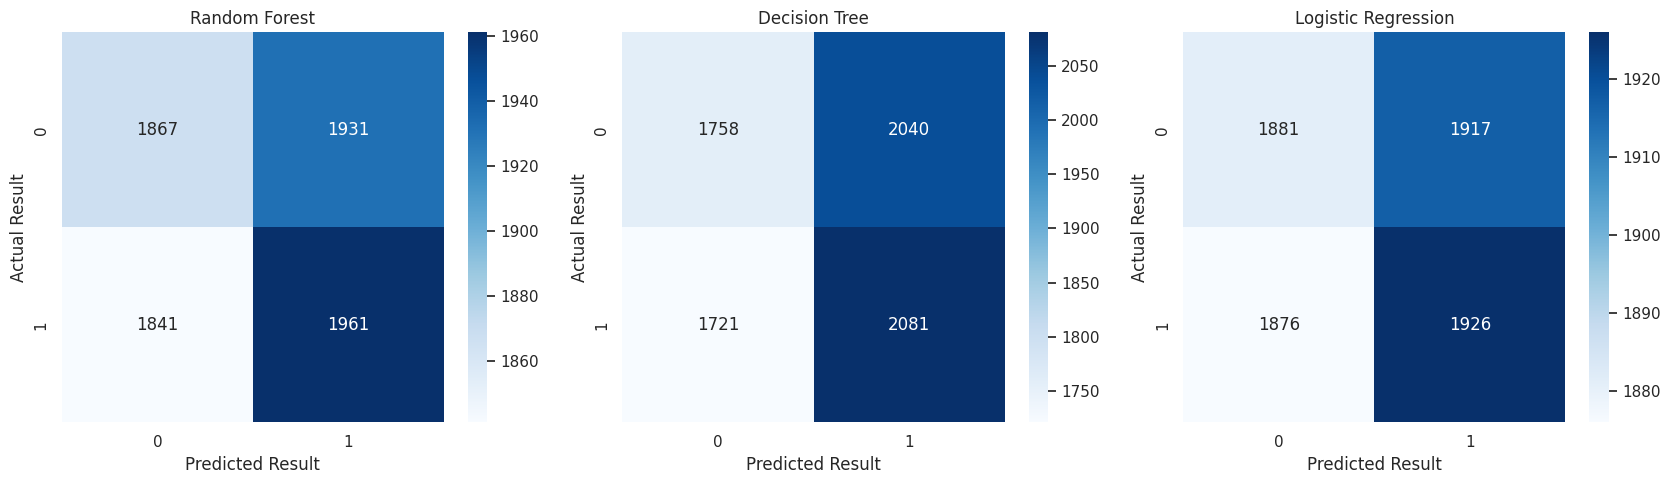

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (name, model) in zip(
    axes,
    trained_models.items()
):

    predictions = model.predict(X_test)

    cm = confusion_matrix(
        y_test,
        predictions
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Result")
    ax.set_ylabel("Actual Result")

plt.tight_layout()
plt.show()

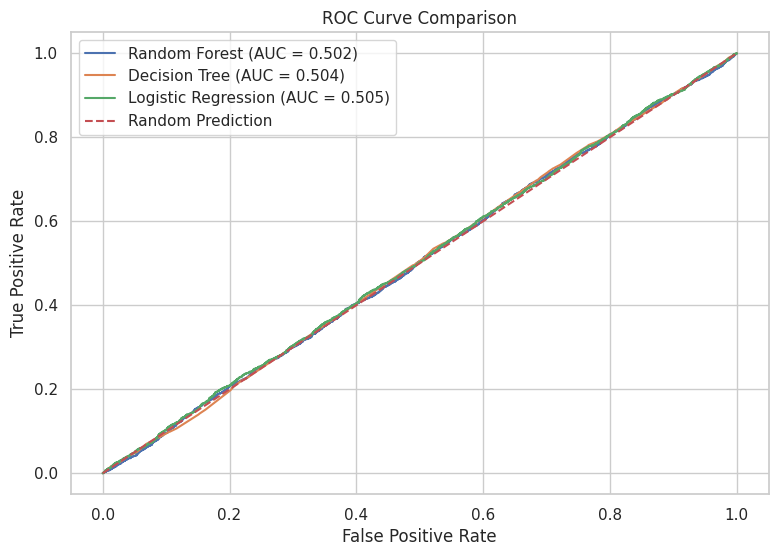

In [ ]:
plt.figure(figsize=(9, 6))

for name, model in trained_models.items():

    probabilities = model.predict_proba(X_test)[:, 1]

    fpr, tpr, thresholds = roc_curve(
        y_test,
        probabilities
    )

    auc = roc_auc_score(
        y_test,
        probabilities
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Prediction"
)

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend()
plt.show()

In [ ]:
best_model_name = results_df.loc[
    results_df["F1 Score"].idxmax(),
    "Algorithm"
]

best_model = trained_models[best_model_name]

print("BEST PERFORMING MODEL")
print("----------------------")

print("Algorithm:", best_model_name)

print(
    "Accuracy:",
    round(
        results_df.loc[
            results_df["Algorithm"] == best_model_name,
            "Accuracy"
        ].iloc[0] * 100,
        2
    ),
    "%"
)

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        best_model.predict(X_test),
        target_names=["Fail", "Pass"]
    )
)

BEST PERFORMING MODEL
----------------------
Algorithm: Decision Tree
Accuracy: 50.51 %

Classification Report:
              precision    recall  f1-score   support

        Fail       0.51      0.46      0.48      3798
        Pass       0.50      0.55      0.53      3802

    accuracy                           0.51      7600
   macro avg       0.51      0.51      0.50      7600
weighted avg       0.51      0.51      0.50      7600



TOP IMPORTANT FEATURES


,Feature,Importance
2,num__Previous Grades,0.325153
1,num__Attendance Rate,0.316920
0,num__Study Hours per Week,0.295382
3,cat__Participation in Extracurricular Activiti...,0.009666
6,cat__Parent Education Level_Bachelor,0.009371
4,cat__Participation in Extracurricular Activiti...,0.009356
9,cat__Parent Education Level_Master,0.008999
8,cat__Parent Education Level_High School,0.008804
7,cat__Parent Education Level_Doctorate,0.008681
5,cat__Parent Education Level_Associate,0.007667


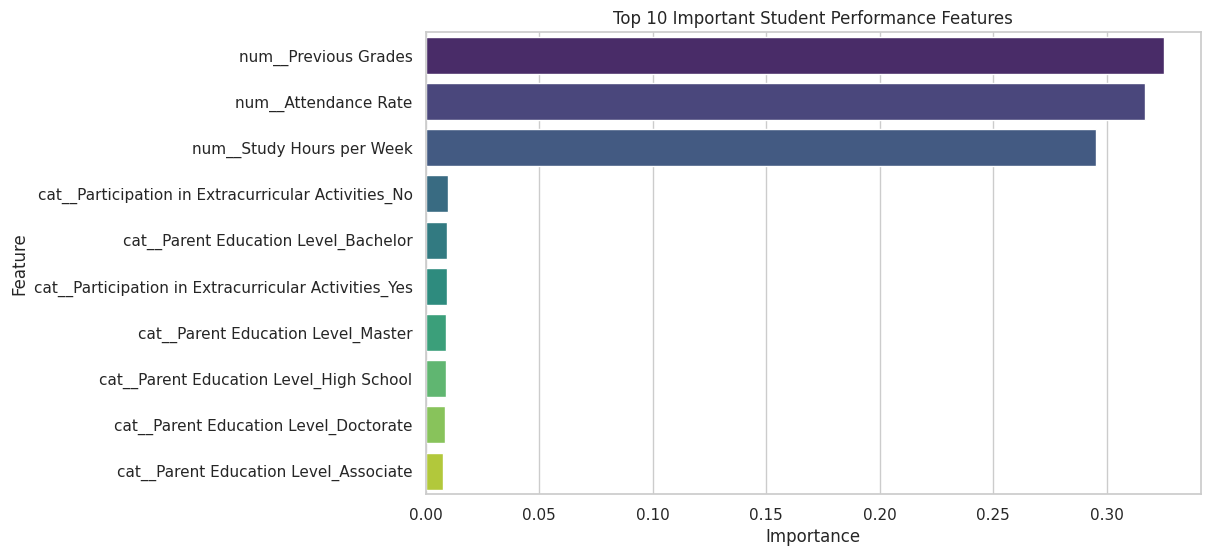

In [ ]:
rf_model = trained_models["Random Forest"]

feature_names = (
    rf_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

importance = rf_model.named_steps[
    "classifier"
].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("TOP IMPORTANT FEATURES")

display(importance_df.head(10))

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df.head(10),
    x="Importance",
    y="Feature",
    hue="Feature",
    palette="viridis",
    legend=False
)

plt.title("Top 10 Important Student Performance Features")
plt.show()

In [ ]:
# Create input fields

study_hours = widgets.FloatSlider(
    value=10,
    min=0,
    max=40,
    step=0.5,
    description="Study Hours:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="500px")
)

attendance = widgets.FloatSlider(
    value=75,
    min=0,
    max=100,
    step=1,
    description="Attendance:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="500px")
)

previous_grades = widgets.FloatSlider(
    value=65,
    min=0,
    max=100,
    step=1,
    description="Previous Grades:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="500px")
)

activities = widgets.Dropdown(
    options=["Yes", "No"],
    value="Yes",
    description="Extracurricular:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="500px")
)

parent_education = widgets.Dropdown(
    options=[
        "High School",
        "Associate",
        "Bachelor",
        "Master",
        "Doctorate"
    ],
    value="Bachelor",
    description="Parent Education:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="500px")
)

predict_button = widgets.Button(
    description="Predict Student Result",
    button_style="success",
    icon="check",
    layout=widgets.Layout(width="250px", height="45px")
)

output = widgets.Output()


# Prediction function

def predict_student(button):

    with output:

        clear_output()

        student_data = pd.DataFrame([{
            "Study Hours per Week": study_hours.value,
            "Attendance Rate": attendance.value,
            "Previous Grades": previous_grades.value,
            "Participation in Extracurricular Activities": activities.value,
            "Parent Education Level": parent_education.value
        }])

        prediction = best_model.predict(student_data)[0]

        probability = best_model.predict_proba(
            student_data
        )[0]

        pass_probability = probability[1] * 100
        fail_probability = probability[0] * 100

        print("=" * 45)
        print("   STUDENT PERFORMANCE PREDICTION")
        print("=" * 45)

        print("\nSelected Algorithm:", best_model_name)

        print("\nPrediction Result:")

        if prediction == 1:
            print("LIKELY TO PASS")
        else:
            print("LIKELY TO FAIL")

        print("\nPass Probability:",
              round(pass_probability, 2), "%")

        print("Fail Probability:",
              round(fail_probability, 2), "%")

        print("\nNote: This is a model-based estimate,")
        print("not a guaranteed academic outcome.")

        # Probability chart

        plt.figure(figsize=(7, 3))

        plt.bar(
            ["Pass", "Fail"],
            [pass_probability, fail_probability],
            color=["seagreen", "indianred"]
        )

        plt.ylabel("Predicted Probability (%)")
        plt.title("Student Result Prediction")
        plt.ylim(0, 100)

        plt.show()


predict_button.on_click(predict_student)


# Dashboard layout

dashboard = widgets.VBox([
    widgets.HTML(
        "<h2>Student Performance Prediction System</h2>"
        "<p>Enter student information to predict academic performance.</p>"
    ),

    study_hours,
    attendance,
    previous_grades,
    activities,
    parent_education,
    predict_button,
    output
])

display(dashboard)

In [ ]:
import joblib

joblib.dump(
    best_model,
    "student_performance_model.pkl"
)

print("Model saved successfully!")

from google.colab import files

files.download("student_performance_model.pkl")

Model saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print("=" * 55)
print("       STUDENT PERFORMANCE PREDICTION")
print("              FINAL REPORT")
print("=" * 55)

print("\nDataset Records:", len(df))
print("Records Used for Training:", len(data))
print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

print("\nAlgorithms Compared:")

for name in trained_models:
    print("-", name)

print("\nBest Performing Algorithm:", best_model_name)

best_result = results_df[
    results_df["Algorithm"] == best_model_name
].iloc[0]

print("\nPerformance Metrics:")

for metric in [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC"
]:
    print(
        metric + ":",
        round(best_result[metric] * 100, 2),
        "%"
    )

print("\n" + "=" * 55)
print("PROJECT EXECUTION COMPLETED SUCCESSFULLY!")
print("=" * 55)

       STUDENT PERFORMANCE PREDICTION
              FINAL REPORT

Dataset Records: 40000
Records Used for Training: 38000
Training Samples: 30400
Testing Samples: 7600

Algorithms Compared:
- Random Forest
- Decision Tree
- Logistic Regression

Best Performing Algorithm: Decision Tree

Performance Metrics:
Accuracy: 50.51 %
Precision: 50.5 %
Recall: 54.73 %
F1 Score: 52.53 %
ROC-AUC: 50.35 %

PROJECT EXECUTION COMPLETED SUCCESSFULLY!
